In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal
from tqdm import tqdm
import math

In [2]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

# n_predata = 50
# def gen_data():
#     X = nr.multivariate_normal(np.zeros(4), np.eye(4), n_predata)
#     y = np.zeros(n_predata)
#     for i in range(n_predata):
#         y[i] = nr.normal(4*X[i,2] + 4*X[i,3], 2.5)
#     #write to file
#     df = pd.DataFrame(X)
#     df['y'] = y
#     df.to_csv('data.csv', index=False)
#     return X, y

# gen_data()

In [ ]:
#read from file
def read_data():
    df = pd.read_csv('data.csv')
    X = df.values[:, 0:-1]
    y = df.values[:, -1]
    return X, y



L = [[0],[1],[2],[3],[0,1],[0,2],[0,3],[1,2],[1,3],[2,3],[0,1,2],[0,1,3],[0,2,3],[1,2,3],[0,1,2,3]]
names = []
for i in range(15):
    strs = ''
    inst = L[i]
    leni = len(inst)
    for j in range(leni):
        strs += str(inst[j]+1)
    strs = "x" + strs + '.npy'
    names.append(strs)

w = nr.beta(1,1,10000)
g = w/(1-w)
dim=1
nc=4
a = np.zeros(1000)
for i in range(1000):
    a[i] = nr.normal(0,g[i],1)

pro = mix_normal(dim)

pro.em_algorithm_1d(a,nc,10)
weights = pro.weights
gs = pro.gs

In [7]:
Truth = []
LiIMCV = []
LiCMC = []
VRFt = []
MSEIMCV=[]
MSECmc=[]

for i in range(15):
    print(names[i])
    input, output = read_data()
    input = input[:, L[i]]
    try: 
        input.shape[1]
    except:
        input = input[:,np.newaxis]
    dim = input.shape[1]
    N = input.shape[0]
    s = 2.5
    cov0 = np.linalg.inv(input.T @ input)

    def true_mean():
        const = (2*np.pi)**(-N/2)*s**(-N)*np.exp(-0.5*s**(-2)*np.sum(output**2))
        t = np.sum(output[:, np.newaxis]*input, axis=0)
        expcoef = 0.5*s**(-2)*(t.T @ cov0 @ t)
        def integrant(x):
            return const*np.exp(expcoef * x / (x+s**2)) *(1+x/s**2)**(-dim/2) * (1+x)**(-2)
        return scipy.integrate.quad(integrant, 0, np.inf)[0]

    tm = true_mean()
    Truth.append(tm)
    nc = 4
    tar = gprior(dim)
    tar.set_parameters(cov0,input, g)
    pro = mix_normal(dim)
    a = tar.sampler(1000)
    try: 
        weights = np.load(names[i])[0]
        gs = np.load(names[i])[1]
        covs = np.array([gs[i]*cov0 for i in range(nc)])
    except:
        pro.em_algorithm(a,nc,input,3001)
        weights = pro.weights
        gs = pro.gs
        covs = np.array([gs[i]*cov0 for i in range(nc)])
        np.save(names[i], [weights, gs])

    Itrnum = 1100
    sample_size = 1000
    target = 'gprior'
    proposal = 'mix_normal'

    epoch = 100
    cmc_mean = []
    imhcv_mean = []

    for j in tqdm(range(epoch)):
        w = nr.beta(1,1,10000)
        g = w/(1-w)
        estcmc = BF(sample_size, weights, cov0, gs, input, output)
        tar = gprior(dim)
        tar.set_parameters(cov0, input, g)
        MyIM = IndMH(Itrnum, dim, target, proposal)
        est = BF(sample_size, weights, cov0, gs, input, output)
        MyIM.set_distribution_parameters(cov0, nc, weights, covs, input, g, gs)
        data = MyIM.IMH()
        est.sample_loader(data[0],data[1],data[2])
        m,v= est.IMCV0()
        imhcv_mean.append(m)
        datacmc = tar.sampler(sample_size)
        estcmc.cmc_loader(datacmc)
        mc,vc = estcmc.CMC()
        cmc_mean.append(mc)

    var_imhcv = np.array(imhcv_mean).var()
    var_cmc = np.array(cmc_mean).var()
    mean_imhcv = np.array(imhcv_mean).mean()
    mean_cmc = np.array(cmc_mean).mean()
    mse_imhcv = var_imhcv + (mean_imhcv - tm)**2
    mse_cmc = var_cmc + (mean_cmc - tm)**2

    vi = -np.log10(var_imhcv)
    vc = -np.log10(var_cmc)
    mi = -np.log10(mse_imhcv)
    mc = -np.log10(mse_cmc)
    meani = -np.log10(mean_imhcv)
    meanc = -np.log10(mean_cmc)
    ti = -np.log10(tm)
    vrfi = var_cmc/var_imhcv

    print('$X_{', names[i][1:-4] ,'}$', \
            ' & ' ,np.round(meani,2), '(', np.round(mi,2), ')',\
            ' & ' ,np.round(meanc,2), '(', np.round(mc,2), ')',\
            ' & ' , np.round(ti,2),\
            ' &',np.round(vrfi,2),'\\\\')
    LiIMCV.append(mean_imhcv)
    LiCMC.append(mean_cmc)
    VRFt.append(var_cmc/var_imhcv)
    MSEIMCV.append(mse_imhcv)
    MSECmc.append(mse_cmc)

x1.npy
2.64260375276513e-87


100%|██████████| 100/100 [00:16<00:00,  5.91it/s]


$X_{ 1 }$  &  86.58 ( 177.71 )  &  86.58 ( 177.03 )  &  86.58  & 4.89 \\
x2.npy
3.484689205836297e-87


100%|██████████| 100/100 [00:16<00:00,  5.90it/s]


$X_{ 2 }$  &  86.46 ( 177.14 )  &  86.46 ( 176.15 )  &  86.46  & 9.76 \\
x3.npy
7.385764860259598e-74


100%|██████████| 100/100 [00:16<00:00,  5.89it/s]


... (21 outputs left out)

100%|██████████| 100/100 [00:20<00:00,  5.00it/s]


$X_{ 234 }$  &  53.48 ( 106.72 )  &  54.03 ( 106.13 )  &  53.58  & 3.84 \\
x1234.npy
1.0658859025291735e-54


100%|██████████| 100/100 [00:20<00:00,  4.99it/s]

$X_{ 1234 }$  &  53.75 ( 107.84 )  &  53.49 ( 104.98 )  &  53.97  & 1091.92 \\


In [ ]:

    # 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15
A = [[0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], #1
     [0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0], #2
     [0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0], #3
     [0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0], #4
     [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0], #5
     [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], #6
     [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0], #7
     [0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0], #8
     [0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0], #9
     [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0], #10
     [0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1], #11
     [0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1], #12
     [0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1], #13
     [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1], #14
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0]] #15

A = np.array(A)
transp = np.sum(A, axis=1)
choices = np.array([i for i in range(15)])
input0, output = read_data()

In [ ]:
nitrs = 10000
init = 0
state = np.array([init,init,init])
sample_size = 10
Itrnum = sample_size+5
nc = 4
target = 'gprior'
proposal = 'mix_normal'

def est_lik(state, input0):
    inputs = input0[:, L[state]]
    try:
        inputs.shape[1]
    except:
        inputs = inputs[:,np.newaxis]
    dim = inputs.shape[1]
    cov0 = np.linalg.inv(inputs.T @ inputs)
    weights = np.load(names[state])[0]
    gs = np.load(names[state])[1]
    covs = np.array([gs[i]*cov0 for i in range(nc)])
    w = nr.beta(1,1,sample_size)
    g = w/(1-w)
    estcmc = BF(sample_size, weights, cov0, gs, inputs, output)
    tar = gprior(dim)
    tar.set_parameters(cov0, inputs, g)
    MyIM = IndMH(Itrnum, dim, target, proposal)
    est = BF(sample_size, weights, cov0, gs, inputs, output)
    MyIM.set_distribution_parameters(cov0, nc, weights, covs, inputs, g, gs)
    data = MyIM.IMH()
    est.sample_loader(data[0],data[1],data[2])
    m,v= est.IMCV0()
    # m0,v0 = est.IM()
    datacmc = tar.sampler(sample_size)
    estcmc.cmc_loader(datacmc)
    mc,vc = estcmc.CMC()
    return m,mc

tar_lik = np.array([est_lik(state[i],input0)[i] for i in range(2)])
pro_lik = np.array([1/transp[state[i]] for i in range(2)])
pmap = np.zeros((15,nitrs+1,2))
print(pmap.shape)  
for i in tqdm(range(nitrs)):
    for j in range(2):
        proposed = np.random.choice(choices, p=A[state[j]]/np.sum(A[state[j]]))
        sample = np.random.uniform(0.0, 1.0, 1)
        tar_lik_now = est_lik(proposed,input0)[j]
        ratio_tar = tar_lik_now/tar_lik[j]
        ratio_pro = transp[proposed]*pro_lik[j]
        ratio = min(1, ratio_tar*ratio_pro)
        if sample <= ratio:
            state[j] = proposed
            tar_lik[j] = tar_lik_now
            pro_lik[j] = 1/transp[state[j]]
        pmap[:,i+1,j] = pmap[:,i,j]
        pmap[state[j],i+1,j] += 1

pmap = pmap/nitrs



(15, 10001, 2)


100%|██████████| 10000/10000 [19:40<00:00,  8.47it/s]


[[0.    0.   ]
 [0.    0.   ]
 [0.    0.003]
 [0.    0.001]
 [0.001 0.   ]
 [0.004 0.005]
 [0.    0.002]
 [0.    0.   ]
 [0.    0.   ]
 [0.59  0.39 ]
 [0.001 0.   ]
 [0.    0.   ]
 [0.226 0.115]
 [0.09  0.019]
 [0.088 0.465]]
['x1.npy', 'x2.npy', 'x3.npy', 'x4.npy', 'x12.npy', 'x13.npy', 'x14.npy', 'x23.npy', 'x24.npy', 'x34.npy', 'x123.npy', 'x124.npy', 'x134.npy', 'x234.npy', 'x1234.npy']
['x12', 'x13', 'x14', 'x23', 'x24', 'x34', 'x123', 'x124', 'x134', 'x234', 'x1234']
(11, 1001)


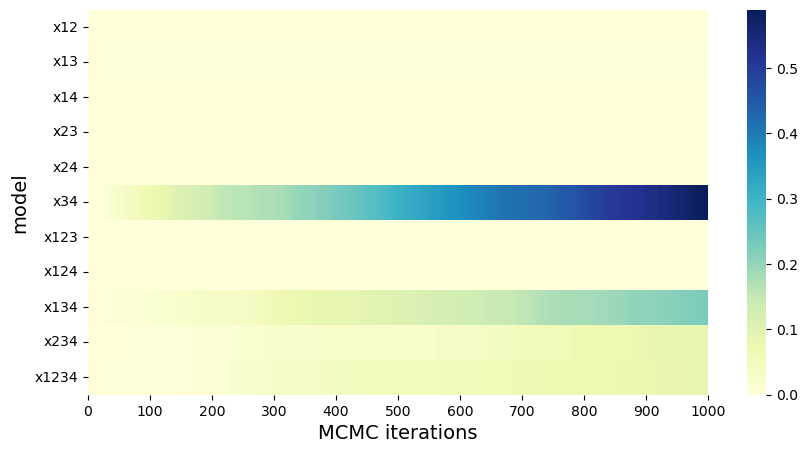

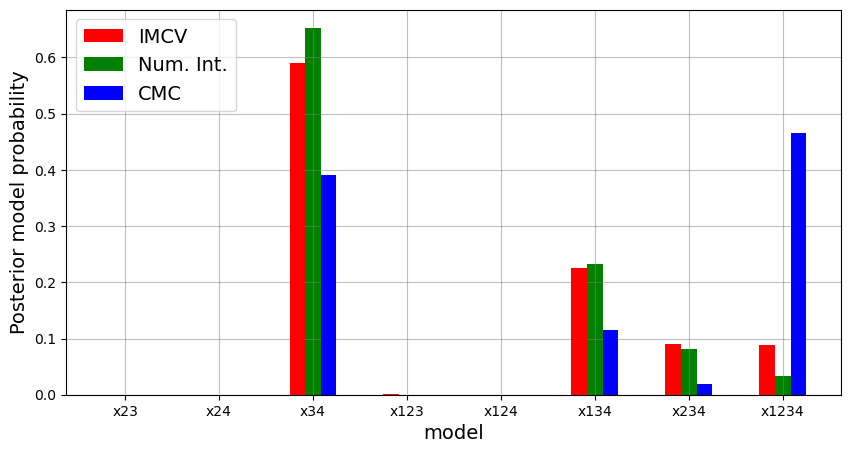

In [ ]:
import seaborn as sns

pmap = np.load('pmap_10000.npy')
print(pmap[:,-1,:])
print(names)
names_new = [names[i][:-4] for i in range(4,15,1)]
print(names_new)
plt.figure(figsize=(10, 5))
ax = sns.heatmap(pmap[4:,:-1,0], cmap="YlGnBu", yticklabels=names_new)
print(pmap[4:,:,0].shape)
num_points = 1100  # Total points
desired_labels = 11  # Desired number of labels

# Determine positions and labels
tick_step = max(1, num_points // desired_labels)
tick_positions = np.arange(0, num_points, tick_step)
tick_labels = [str(i) for i in tick_positions]

# Setting the ticks in the plot
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0)
# plt.title('density convergence of the model selection with IMCV estimator')
ax.set_xlabel('MCMC iterations', fontsize=14)
ax.set_ylabel('model', fontsize=14)
plt.savefig('heatmap_10000.png', format='png', bbox_inches='tight')
plt.show()


labels0 = ['x23', 'x24', 'x34', 'x123', 'x124', 'x134', 'x234', 'x1234']
pmf_imcv = pmap[:,-1,0]
pmf_cmc = pmap[:,-1,1]
pmf_t = Truth/np.sum(Truth)
X = np.arange(8)*1.5
width = 0.25
plt.figure(figsize=(10,5))
# pmf_imcv = np.load('imcv.npy')
plt.grid(True,color='gray', zorder=0, alpha=0.5)
plt.bar(X-width,pmf_imcv[7:],width,color='r',zorder =3)
# plt.bar(X-0.5*width,pmf_im,width,color='g')
plt.bar(X,pmf_t[7:],width,color='g',zorder =1)
plt.bar(X+width,pmf_cmc[7:],width,color='b',zorder =2)

plt.xticks(X, labels0)
plt.legend(['IMCV','Num. Int.','CMC'], loc='upper left', fontsize=14)
# plt.title('pmf of the model selection')
plt.xlabel('model', fontsize=14)
plt.ylabel('Posterior model probability', fontsize=14)

plt.savefig('bar_10000.pdf', format='pdf', bbox_inches='tight')



plt.show()